In [2]:
import pandas as pd
import numpy as np
import tensorflow as tf
from pathlib import Path

I0000 00:00:1775140311.407479   26408 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1775140311.723715   26408 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1775140313.100517   26408 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [3]:
# loading dataset
data = Path("./PetImages")
list(data.glob("**/*.jpg"))[:5]

[PosixPath('PetImages/Dog/3188.jpg'),
 PosixPath('PetImages/Dog/8182.jpg'),
 PosixPath('PetImages/Dog/9836.jpg'),
 PosixPath('PetImages/Dog/6794.jpg'),
 PosixPath('PetImages/Dog/3485.jpg')]

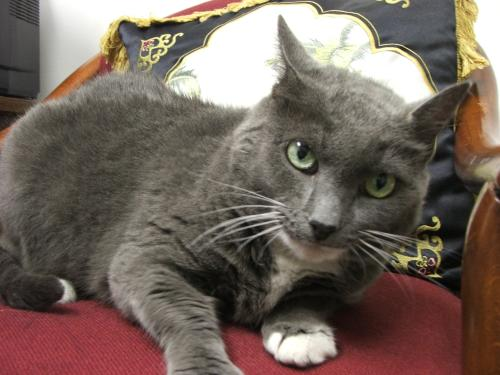

In [4]:
from PIL import Image
Image.open(
    str(
        list(
            data.glob("Cat/*.jpg")
        )[5]
    )
)

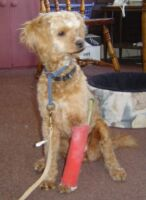

In [5]:
Image.open(
    str(
        list(
            data.glob("Dog/*.jpg")
        )[5]
    )
)

In [1]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

train_gen = datagen.flow_from_directory(
  './PetImages',
  target_size=(100, 100),
  batch_size=32,
  class_mode='binary',
  subset='training'
)

val_gen = datagen.flow_from_directory(
  './PetImages',
  target_size=(100, 100),
  batch_size=32,
  class_mode='binary',
  subset='validation'
)

I0000 00:00:1775140499.597198   28285 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1775140499.908780   28285 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1775140501.273644   28285 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Found 20000 images belonging to 2 classes.
Found 4998 images belonging to 2 classes.


In [9]:
print(len(X))

24997


In [ ]:
X = np.array(X, dtype=np.uint8) / 255.0
Y = np.array(Y) / 255.0

In [ ]:
X.shape

(24997, 100, 100, 3)

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

In [ ]:
model = tf.keras.Sequential([
    # image normalization
    tf.keras.layers.Conv2D(32,(3,3),padding='same',activation='relu',input_shape=(200,200,3)),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64,(3,3),padding='same',activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    # actual learning
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128,activation='relu',kernel_regularizer=tf.keras.regularizers.l2(0.05)),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(64,activation='relu',kernel_regularizer=tf.keras.regularizers.l2(0.05)),
    tf.keras.layers.Dropout(0.5), 

    # output number
    tf.keras.layers.Dense(1,activation='sigmoid'),
])

/home/meyigi/personal/personal/tech-playground/artificial_intelligence/.venv/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1775139954.196907   23189 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1775139954.198361   24808 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1775139954.219512   23189 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]

)

In [ ]:
# model.fit(X_train, y_train, epochs=5)